# Predicción de tráfico vehicular y estimación de ingresos de peaje – Trabajo de integrador
Concesión vial Buga – Tuluá – La Paila – La Victoria · Metodología CRISP-DM





## FASE 1 · Comprensión del negocio

**Problema.** La estimación de los ingresos de peaje de una concesión de primera generación depende de proyectar bien el tráfico; los métodos tradicionales (series de tiempo y regresión) tienen limitaciones ante eventos atípicos como el cambio de clima o la pandemia y relaciones no lineales.

**Objetivo.** Construir y comparar modelos predictivos del tráfico mensual del tramo y, con el mejor, proyectar los ingresos por recaudo:

$$\text{Ingresos} = \sum_{i=1}^{5} \text{Tráfico}_i \cdot \text{Tarifa}_i + \sum_{EA=1}^{4} \text{Ejes}_{EA}\cdot \text{Tarifa}_{EA} \qquad \text{Tarifa}_T = \text{Tarifa}_{T-1}\,(1+\text{Var.\%IPC}_{T-1})\ \ (\text{redondeada a la centena})$$

**Criterios de éxito (definidos antes de modelar).**
1. El mejor modelo debe superar al *naive estacional* (mismo mes del año anterior) en MAPE sobre la validación temporal.
2. Se reporta MAE, RMSE y MAPE por horizonte (1-3, 4-6, 7-12 meses).
3. Se produce la proyección de ingresos por categoría, periodo y escenario (optimista, base, pesimista) y un análisis de sensibilidad.

**Alcance y supuestos.** El ingreso calculado es *teórico* (vehículos × tarifa): no descuenta exentos ni evasión. Las categorías sin tarifa publicada se asumen sin ingreso. La serie de tráfico llega hasta diciembre de 2025 y no incluye las categorías especiales (exentas).

## FASE 2 · Comprensión de los datos

In [1]:
import warnings, itertools, time, os, re          # >>> MODIFICADO: se agrega re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.easter import easter
import holidays

try:
    from statsmodels.tsa.seasonal import STL
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    HAS_SM = True
except ImportError:
    HAS_SM = False
    print("statsmodels no está instalado: se omiten STL, SARIMA/SARIMAX y Holt-Winters.")


# >>> NUEVO: XGBoost (pip install xgboost)
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost no está instalado: ejecuta  pip install xgboost  en la terminal de VS Code y reinicia el kernel.")

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40)

DATA_DIR = r"C:\Users\maria\OneDrive\Escritorio\Data Set Trafico\Data Set"     # >>> MODIFICADO: carpeta local con los archivos
OUT_DIR = os.path.join(DATA_DIR, "resultados")                                      # >>> MODIFICADO: carpeta de resultados (dentro de Data Set)
os.makedirs(OUT_DIR, exist_ok=True)

F_TRAFICO = os.path.join(DATA_DIR, "BD_TraficoTotal.xlsx")
F_TARIFA = os.path.join(DATA_DIR, "BD_Tarifa.xlsx")
F_IPC = os.path.join(DATA_DIR, "BD_Inflación.xlsx")
F_PUERTO = os.path.join(DATA_DIR, "Trafico_Portuario_Marítimo_En_Colombia_20260923.csv")
F_ISE = os.path.join(DATA_DIR, "anex-ISE-9actividades-ago2026.xlsx")



FIN_SERIE = "2025-12-01"               # >>> NUEVO: la serie del dataset maestro llega hasta diciembre de 2025
VENTANA_INICIO = "2006-01-01"            # ventana de modelado (la serie tiene datos reales desde 2004)
# Eventos atípicos (ajusta las fechas si lo consideras necesario)
COVID = ("2020-03-01", "2020-12-01")     # confinamiento y recuperación
PARO = ("2021-04-01", "2021-06-01")      # paro nacional / bloqueos (afectó Valle y Buenaventura)

In [7]:
import os
import pandas as pd

def a_mes(s):
    """Normaliza cualquier fecha al primer día de su mes."""
    return pd.to_datetime(s).dt.to_period("M").dt.to_timestamp()

# >>> MODIFICADO: Si no encuentra los archivos en la ruta local de Windows, busca en el directorio actual de Colab
faltan = [p for p in (F_TRAFICO, F_TARIFA, F_IPC, F_PUERTO, F_ISE) if not os.path.exists(p)]
if faltan:
    # Intenta redefinir las rutas usando el directorio actual (Colab)
    F_TRAFICO = "BD_TraficoTotal.xlsx"
    F_TARIFA = "BD_Tarifa.xlsx"
    F_IPC = "BD_Inflación.xlsx"
    F_PUERTO = "Trafico_Portuario_Marítimo_En_Colombia_20260923.csv"
    F_ISE = "anex-ISE-9actividades-ago2026.xlsx"

    # Validar de nuevo en el directorio de Colab
    faltan_colab = [p for p in (F_TRAFICO, F_TARIFA, F_IPC, F_PUERTO, F_ISE) if not os.path.exists(p)]
    if faltan_colab:
        raise FileNotFoundError("No se encontraron estos archivos tampoco en el entorno de Colab:\n  " + "\n  ".join(faltan_colab))

# --- 1.1 Tráfico por estación, mes y categoría (formato largo) ---
tr = pd.read_excel(F_TRAFICO)
tr.columns = ["estacion", "fecha", "categoria", "vehiculos"]
tr["fecha"] = a_mes(tr["fecha"])

# --- 1.2 Tarifas por estación, año y categoría ---
tf = pd.read_excel(F_TARIFA)
tf.columns = ["estacion", "anio", "categoria", "tarifa"]

# --- 1.3 IPC (índice y variación 12 meses) ---
ipc = pd.read_excel(F_IPC)
ipc.columns = ["fecha", "ipc_indice", "ipc_var12"]
ipc["fecha"] = a_mes(ipc["fecha"])

# --- 1.4 Tráfico portuario de Buenaventura ---
# El CSV viene separado por ";" y con el punto como separador de miles (ej. 64.461 = 64461; 2.021 = 2021)
pt = pd.read_csv(F_PUERTO, sep=";", dtype=str)
pt.columns = pt.columns.str.strip()
cols_carga = ["EXPORTACION", "IMPORTACIÓN", "TRANSBORDO", "TRANSITO INTERNACIONAL",
              "FLUVIAL", "CABOTAJE", "MOVILIZACIONES A BORDO", "TRANSITORIA"]
for c in cols_carga + ["AÑO VIGENCIA", "MES VIGENCIA"]:
    pt[c] = pd.to_numeric(pt[c].str.strip().str.replace(".", "", regex=False))
pt["fecha"] = pd.to_datetime(dict(year=pt["AÑO VIGENCIA"], month=pt["MES VIGENCIA"], day=1))
# >>> MODIFICADO: del puerto solo se usan importaciones y exportaciones
port = pt.groupby("fecha").agg(port_export=("EXPORTACION", "sum"), port_import=("IMPORTACIÓN", "sum"))


# --- 1.5 ISE (DANE)
MESES_ES = {"Enero": 1, "Febrero": 2, "Marzo": 3, "Abril": 4, "Mayo": 5, "Junio": 6, "Julio": 7,
            "Agosto": 8, "Septiembre": 9, "Octubre": 10, "Noviembre": 11, "Diciembre": 12}

def leer_cuadro_ise(path, hoja):
    '''Lee un cuadro del anexo del ISE (años en una fila, meses en la siguiente) y devuelve un DataFrame mensual.'''
    import openpyxl
    filas = list(openpyxl.load_workbook(path, read_only=True, data_only=True)[hoja].iter_rows(values_only=True))
    i0 = next(i for i, r in enumerate(filas) if r[0] == "Concepto")
    anios, meses = filas[i0], filas[i0 + 1]
    cols, anio = [], None
    for j in range(1, len(meses)):
        if anios[j] is not None:                                   # los años vienen como 2024p, 2026pr, etc.
            anio = int("".join(ch for ch in str(anios[j]) if ch.isdigit())[:4])
        if meses[j] in MESES_ES:
            cols.append((j, pd.Timestamp(anio, MESES_ES[meses[j]], 1)))
    datos = {}
    for r in filas[i0 + 2:]:
        if r[0] and str(r[0]).startswith("Fuente"):
            break
        if r[0]:
            datos[r[0]] = [r[j] for j, _ in cols]
    return pd.DataFrame(datos, index=[f for _, f in cols]).astype(float)

ise_o = leer_cuadro_ise(F_ISE, "Cuadro 1")      # serie original
COL_ISE = [c for c in ise_o.columns if c.startswith("Indicador de Seguimiento")][0]
COL_CT = [c for c in ise_o.columns if c.startswith("Comercio al por mayor")][0]     # comercio, transporte, alojamiento
# >>> NUEVO: ISE de Agricultura (primera columna del cuadro cuyo nombre empieza por "Agricultura")
_agr = [c for c in ise_o.columns if c.lower().startswith("agricultura")]
assert _agr, f"No se encontró la columna de Agricultura en el ISE. Columnas disponibles: {list(ise_o.columns)}"
COL_AGR = _agr[0]
# >>> MODIFICADO: el ISE se limita a las tres series del dataset maestro
ise = pd.DataFrame({"ise": ise_o[COL_ISE], "ise_comercio_transp": ise_o[COL_CT], "ise_agricultura": ise_o[COL_AGR]})

# --- 1.6 Chequeos de calidad ---

print("Tráfico:", tr.shape, "| duplicados:", tr.duplicated(["estacion", "fecha", "categoria"]).sum(),
      "| nulos:", tr.isna().sum().sum())
print("Estaciones:", tr["estacion"].unique().tolist(), "| categorías:", tr["categoria"].nunique())
print("Tarifas:", tf.shape, "| duplicados:", tf.duplicated(["estacion", "anio", "categoria"]).sum())
print("Puerto:", port.index.min().date(), "→", port.index.max().date(), "| meses:", len(port))
print("ISE:", ise.index.min().date(), "→", ise.index.max().date(), "| meses:", len(ise), "| nulos:", int(ise.isna().sum().sum()))

Tráfico: (10640, 4) | duplicados: 0 | nulos: 0
Estaciones: ['Betania', 'Uribe'] | categorías: 14
Tarifas: (896, 4) | duplicados: 0
Puerto: 2018-01-01 → 2026-06-01 | meses: 102
ISE: 2005-01-01 → 2026-08-01 | meses: 260 | nulos: 0


## FASE 3 · Preparación y análisis de los datos  *(Objetivo específico 1)*
### 3.1 Dataset maestro mensual
Se agrega todo a **frecuencia mensual** y la serie llega hasta **diciembre de 2025**. El dataset maestro contiene **solo estas variables**: tráfico total, tráfico por estación (Betania y Uribe) y por categoría (Cat. 1-5) y ejes adicionales (EA), IPC índice, ISE (total, comercio y transporte, agricultura), carga del puerto de Buenaventura (importaciones, exportaciones e I+E) y calendario (N festivos, N fines de semana). **No incluye categorías especiales (exentas) ni agrupaciones livianos/pesados.**

La variable objetivo es el **tráfico total**. Internamente se modela el **TPD** (tráfico promedio diario = total / días del mes) para que los meses de 28, 30 y 31 días sean comparables; ese cálculo, las dummies de COVID/paro, las tarifas y el ingreso teórico son **variables auxiliares** que se derivan aparte y no hacen parte del dataset maestro.

In [8]:
# ===== 3.1 Dataset maestro mensual =====
# >>> MODIFICADO: el dataset maestro contiene SOLO las variables definidas (MAESTRO_A_INTERNO), sin categorías especiales
# (exentas, "Cat. X E") ni agrupaciones livianos/pesados, y llega hasta FIN_SERIE (dic-2025).
# Todo lo demás que necesitan los modelos (días del mes, tpd, COVID/paro, tarifas, ingreso teórico) se calcula aparte
# como variables AUXILIARES en `m` y NO forma parte del dataset maestro.

def calendario(indice):
    anios = range(indice.year.min(), indice.year.max() + 2)
    co = holidays.CO(years=anios)
    filas = []
    for d_ in indice:
        dias_ = pd.date_range(d_, d_ + pd.offsets.MonthEnd(0))
        jueves_santo = pd.Timestamp(easter(d_.year)) - pd.Timedelta(days=3)
        filas.append(dict(
            dias=len(dias_),
            n_festivos=sum(x.date() in co for x in dias_),
            n_findes=int((dias_.dayofweek >= 5).sum()),
            semana_santa=int(jueves_santo.year == d_.year and jueves_santo.month == d_.month),
        ))
    return pd.DataFrame(filas, index=indice)

def eventos(indice):
    e = pd.DataFrame(index=indice)
    e["covid"] = ((indice >= COVID[0]) & (indice <= COVID[1])).astype(int)
    e["paro"] = ((indice >= PARO[0]) & (indice <= PARO[1])).astype(int)
    return e

# --- 1) Filtros sobre el tráfico: serie hasta FIN_SERIE y sin categorías especiales ---
n0 = len(tr)
tr = tr[tr["fecha"] <= FIN_SERIE].copy()
_especial = tr["categoria"].str.strip().str.match(r"^Cat\.\s*(IV|V|I{1,3})\s+E$")
print(f"Registros fuera de la serie (> {FIN_SERIE[:7]}): {n0 - len(tr)} | de categorías especiales excluidos: {int(_especial.sum())}")
tr = tr[~_especial].copy()

# --- 2) Clasificación: Cat. 1-5 y EA (suma de todos los ejes adicionales: agrícola, grúa, remolque y carrocería) ---
def grupo_num(c):
    c = str(c).strip()
    if c.startswith("Eje"):
        return "EA"
    mt = re.match(r"Cat\.\s*(IV|V|I{1,3})$", c)
    return {"I": "1", "II": "2", "III": "3", "IV": "4", "V": "5"}[mt.group(1)] if mt else None

tr["cat_num"] = tr["categoria"].map(grupo_num)
_sin = tr.loc[tr["cat_num"].isna(), "categoria"].unique().tolist()
assert not _sin, f"Categorías sin clasificar: {_sin}"
por_est_cat = tr.pivot_table(index="fecha", columns=["estacion", "cat_num"], values="vehiculos", aggfunc="sum")

# --- 3) Dataset maestro (nombres de columna = los de la tabla de variables) ---
ESTACIONES = {"Betania": "Bet", "Uribe": "Uri"}
MAESTRO_A_INTERNO = {                     # nombre en el dataset maestro -> nombre interno usado en el código
    "Tráfico Total": "trafico_total",
    "Tráfico Betania": "trafico_betania",
    **{f"Tráfico Cat {c} - Bet": f"trafico_betania_cat{c}" for c in range(1, 6)},
    "Tráfico EA - Bet": "trafico_betania_ea",
    "Tráfico Uribe": "trafico_uribe",
    **{f"Tráfico Cat {c} - Uri": f"trafico_uribe_cat{c}" for c in range(1, 6)},
    "Tráfico EA - Uri": "trafico_uribe_ea",
    "IPC índice": "ipc_indice",
    "ISE total": "ise",
    "ISE Com. y Transp.": "ise_comercio_transp",
    "ISE Agricultura": "ise_agricultura",
    "Imp. B/tura": "port_import",
    "Exp. B/tura": "port_export",
    "I+E B/tura": "port_ie",
    "N festivos": "n_festivos",
    "N fds (S + D)": "n_findes",
}

idx = pd.date_range(tr["fecha"].min(), FIN_SERIE, freq="MS")
dm = pd.DataFrame(index=idx)
dm.index.name = "Fecha"
for est, ab in ESTACIONES.items():
    cols_est = []
    for c in ["1", "2", "3", "4", "5", "EA"]:
        nombre = f"Tráfico EA - {ab}" if c == "EA" else f"Tráfico Cat {c} - {ab}"
        dm[nombre] = por_est_cat[(est, c)]
        cols_est.append(nombre)
    dm[f"Tráfico {est}"] = dm[cols_est].sum(axis=1)               # estación = Cat. 1-5 + EA
dm["Tráfico Total"] = dm[["Tráfico Betania", "Tráfico Uribe"]].sum(axis=1)

# La serie tiene ceros hasta que empieza el registro real: se descartan esos meses
primer_mes = dm.index[dm["Tráfico Total"] > 0].min()
dm = dm.loc[primer_mes:].copy()
cols_trafico = [c for c in dm.columns if c.startswith("Tráfico")]
dm[cols_trafico] = dm[cols_trafico].fillna(0)                    # categoría sin registros en el mes = 0 vehículos
assert (dm["Tráfico Total"] > 0).all(), "Hay meses sin tráfico dentro de la serie"
print("Primer mes con tráfico registrado:", primer_mes.date(), "| último:", dm.index.max().date())

# IPC, ISE, puerto y calendario
dm["IPC índice"] = ipc.set_index("fecha")["ipc_indice"]
dm["ISE total"] = ise["ise"]
dm["ISE Com. y Transp."] = ise["ise_comercio_transp"]
dm["ISE Agricultura"] = ise["ise_agricultura"]
dm["Imp. B/tura"] = port["port_import"]                           # solo existe 2018-01 → 2026-06
dm["Exp. B/tura"] = port["port_export"]
dm["I+E B/tura"] = dm["Imp. B/tura"] + dm["Exp. B/tura"]
_cal = calendario(dm.index)
dm["N festivos"] = _cal["n_festivos"]
dm["N fds (S + D)"] = _cal["n_findes"]

dataset_maestro = dm[list(MAESTRO_A_INTERNO)]                    # orden y variables exactamente como se definieron

# --- 4) Base de modelado `m`: dataset maestro (nombres internos) + variables AUXILIARES ---
m = dataset_maestro.rename(columns=MAESTRO_A_INTERNO)
m.index.name = "fecha"
m = m.join(calendario(m.index)[["dias", "semana_santa"]]).join(eventos(m.index))
m["tpd"] = m["trafico_total"] / m["dias"]
m = m.join(ipc.set_index("fecha")[["ipc_var12"]])                # variación anual del IPC (para el reajuste y como regresora)
m["trafico_cat5"] = m["trafico_betania_cat5"] + m["trafico_uribe_cat5"]          # auxiliar solo para el EDA

# Tarifa Cat. I e ingreso teórico = vehículos × tarifa (estación, año, categoría)
t1 = tf[tf["categoria"] == "Cat. I"].pivot_table(index="anio", columns="estacion", values="tarifa")
t1.columns = [f"tarifa_cat1_{c.lower()}" for c in t1.columns]
m["anio"] = m.index.year
m = m.join(t1, on="anio").drop(columns="anio")
m["tarifa_cat1_prom"] = m[t1.columns].mean(axis=1)
m["tarifa_cat1_real"] = m["tarifa_cat1_prom"] * m["ipc_indice"].iloc[-1] / m["ipc_indice"]   # $ constantes del último mes (dic-2025)

x = tr.assign(anio=tr["fecha"].dt.year).merge(tf, on=["estacion", "anio", "categoria"], how="left")
# Las categorías "Eje" solo faltan en BD_Tarifa en 1995-1998. Supuesto: sin tarifa publicada = no genera ingreso.
sin_tarifa = x[x["tarifa"].isna() & (x["fecha"] >= primer_mes)]
print("Tráfico (≥2004) sin tarifa:", f"{sin_tarifa['vehiculos'].sum() / x[x['fecha'] >= primer_mes]['vehiculos'].sum():.2%}",
      "→", sin_tarifa.groupby(["estacion", "categoria"]).size().index.tolist())
x["ingreso"] = x["vehiculos"] * x["tarifa"].fillna(0)
m["ingreso_teorico"] = x.groupby("fecha")["ingreso"].sum()
m["tarifa_media_pond"] = m["ingreso_teorico"] / m["trafico_total"]

print("Dataset maestro:", dataset_maestro.shape, "| base de modelado (con auxiliares):", m.shape)
dataset_maestro.tail(6).T

Registros fuera de la serie (> 2025-12): 224 | de categorías especiales excluidos: 3720
Primer mes con tráfico registrado: 2004-01-01 | último: 2025-12-01
Tráfico (≥2004) sin tarifa: 0.00% → []
Dataset maestro: (264, 24) | base de modelado (con auxiliares): (264, 37)


Fecha,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01
Tráfico Total,1.242778e+06,1.236289e+06,1.093714e+06,1.228016e+06,1.203530e+06,1.363500e+06
Tráfico Betania,6.887470e+05,6.835820e+05,6.185910e+05,6.769380e+05,6.662010e+05,7.530840e+05
Tráfico Cat 1 - Bet,3.717960e+05,3.812820e+05,3.268930e+05,3.714210e+05,3.670720e+05,4.507510e+05
Tráfico Cat 2 - Bet,1.735200e+05,1.659880e+05,1.621820e+05,1.713240e+05,1.640310e+05,1.673820e+05
Tráfico Cat 3 - Bet,3.872500e+04,3.611900e+04,3.521700e+04,3.612900e+04,3.490800e+04,3.434000e+04
Tráfico Cat 4 - Bet,2.252800e+04,2.174200e+04,1.998400e+04,2.097500e+04,2.143200e+04,2.201600e+04
Tráfico Cat 5 - Bet,7.270300e+04,6.857300e+04,6.535400e+04,7.184900e+04,7.100700e+04,6.570500e+04
Tráfico EA - Bet,9.475000e+03,9.878000e+03,8.961000e+03,5.240000e+03,7.751000e+03,1.289000e+04
Tráfico Uribe,5.540310e+05,5.527070e+05,4.751230e+05,5.510780e+05,5.373290e+05,6.104160e+05
Tráfico Cat 1 - Uri,2.733920e+05,2.852090e+05,2.192080e+05,2.770050e+05,2.697430e+05,3.447670e+05


### 3.2 Guardar el dataset maestro y el diccionario de variables

In [9]:
# >>> MODIFICADO: se guarda el dataset maestro (solo las variables definidas, hasta dic-2025) y su diccionario.
# La base de modelado `m` (con variables auxiliares: dias, tpd, covid, paro, tarifas, ingreso teórico) va en una hoja aparte.

# Chequeos de consistencia contra los datos crudos (sin categorías especiales, hasta FIN_SERIE)
_crudo = tr[tr["fecha"] >= primer_mes]
assert abs(dataset_maestro["Tráfico Total"].sum() - _crudo["vehiculos"].sum()) < 1, "Tráfico Total no coincide con los datos crudos"
for est, ab in ESTACIONES.items():
    assert abs(dataset_maestro[f"Tráfico {est}"].sum() - _crudo.loc[_crudo["estacion"] == est, "vehiculos"].sum()) < 1
    partes = dataset_maestro[[f"Tráfico Cat {c} - {ab}" for c in range(1, 6)] + [f"Tráfico EA - {ab}"]].sum(axis=1)
    assert (partes - dataset_maestro[f"Tráfico {est}"]).abs().max() < 1
assert dataset_maestro.index.max() == pd.Timestamp(FIN_SERIE)
print("Chequeos OK | serie:", dataset_maestro.index.min().date(), "→", dataset_maestro.index.max().date(),
      f"({len(dataset_maestro)} meses)")
print("Nulos por variable (solo puerto antes de 2018 y/o ISE antes de 2005 es esperable):")
print(dataset_maestro.isna().sum()[lambda s: s > 0].to_string())

diccionario = pd.DataFrame([
    ("Fecha", "Primer día del mes"),
    ("Tráfico Total", "VARIABLE OBJETIVO: vehículos del mes (Betania + Uribe; Cat. 1-5 y ejes adicionales, sin categorías especiales)"),
    ("Tráfico Betania / Tráfico Uribe", "Vehículos del mes por estación (Cat. 1-5 + EA)"),
    ("Tráfico Cat 1..5 - Bet / - Uri", "Vehículos por categoría y estación (no incluye las categorías especiales/exentas \"E\")"),
    ("Tráfico EA - Bet / - Uri", "Suma de todos los ejes adicionales de la estación (agrícola, grúa, remolque y carrocería)"),
    ("IPC índice", "IPC (índice empalmado DANE)"),
    ("ISE total", "ISE – Indicador de Seguimiento a la Economía (DANE), serie original, base 2015 = 100"),
    ("ISE Com. y Transp.", "ISE de la agrupación Comercio, reparación de vehículos, transporte y almacenamiento, alojamiento y comidas"),
    ("ISE Agricultura", "ISE de la agrupación Agricultura, ganadería, caza, silvicultura y pesca"),
    ("Imp. B/tura", "Carga de importación movilizada en el puerto de Buenaventura (unidad del CSV, presumiblemente toneladas)"),
    ("Exp. B/tura", "Carga de exportación movilizada en el puerto de Buenaventura"),
    ("I+E B/tura", "Importación + exportación (no incluye transbordo, tránsito, cabotaje, etc.)"),
    ("N festivos", "Número de festivos de Colombia en el mes"),
    ("N fds (S + D)", "Número de sábados + domingos del mes"),
], columns=["variable", "descripcion"])

dataset_maestro.reset_index().to_csv(f"{OUT_DIR}/dataset_maestro_mensual.csv", index=False, encoding="utf-8-sig")
with pd.ExcelWriter(f"{OUT_DIR}/dataset_maestro_mensual.xlsx") as w:
    dataset_maestro.reset_index().to_excel(w, sheet_name="maestro", index=False)
    diccionario.to_excel(w, sheet_name="diccionario", index=False)
    m.reset_index().to_excel(w, sheet_name="base_modelado", index=False)      # incluye variables auxiliares
print("Dataset guardado")

Chequeos OK | serie: 2004-01-01 → 2025-12-01 (264 meses)
Nulos por variable (solo puerto antes de 2018 y/o ISE antes de 2005 es esperable):
ISE total              12
ISE Com. y Transp.     12
ISE Agricultura        12
Imp. B/tura           168
Exp. B/tura           168
I+E B/tura            168
Dataset guardado


### 3.3 Análisis exploratorio

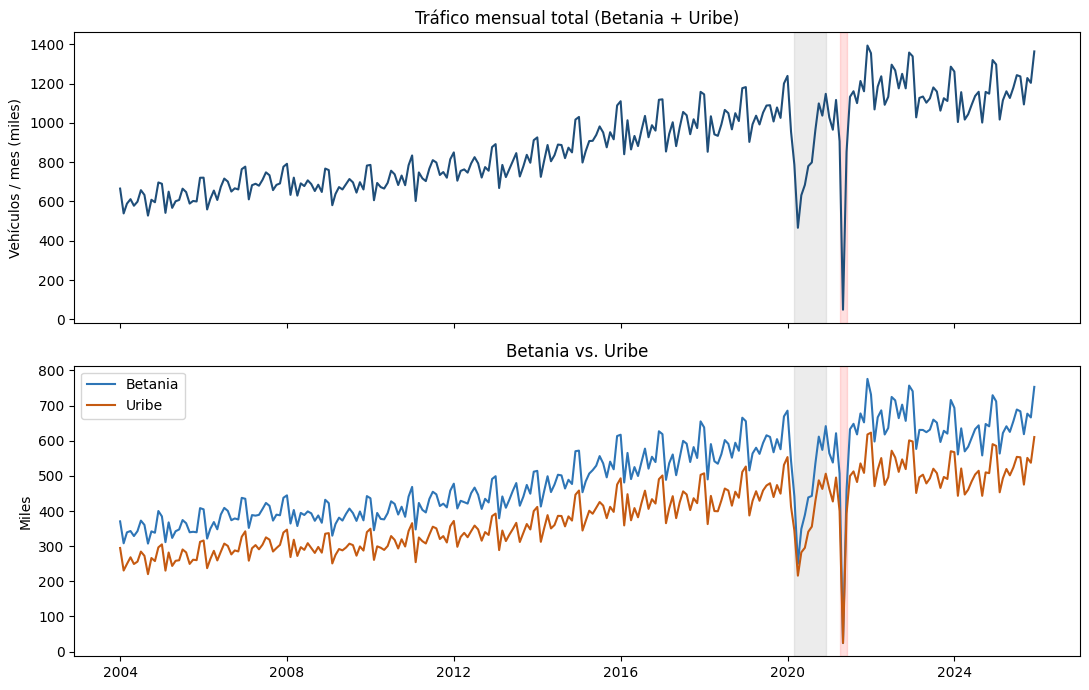

Índice estacional (TPD mes / TPD promedio del año), 2006-2025:
fecha
1     1.105
2     0.946
3     0.959
4     0.953
5     0.872
6     0.984
7     1.024
8     1.010
9     0.976
10    1.018
11    1.014
12    1.138


In [10]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(m.index, m["trafico_total"] / 1e3, color="#1f4e79")
ax[0].set_ylabel("Vehículos / mes (miles)"); ax[0].set_title("Tráfico mensual total (Betania + Uribe)")
# >>> MODIFICADO: por estación (ya no hay livianos/pesados)
ax[1].plot(m.index, m["trafico_betania"] / 1e3, label="Betania", color="#2e75b6")
ax[1].plot(m.index, m["trafico_uribe"] / 1e3, label="Uribe", color="#c55a11")
ax[1].set_ylabel("Miles"); ax[1].legend(); ax[1].set_title("Betania vs. Uribe")
for a in ax:
    a.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15)
    a.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_serie_historica.png", dpi=130); plt.show()

# Estacionalidad: TMD relativo a la media anual
z = m.loc["2006":"2025", "tpd"]
perfil = (z / z.groupby(z.index.year).transform("mean")).groupby(z.index.month).mean()
print("Índice estacional (TPD mes / TPD promedio del año), 2006-2025:")
print(perfil.round(3).to_string())

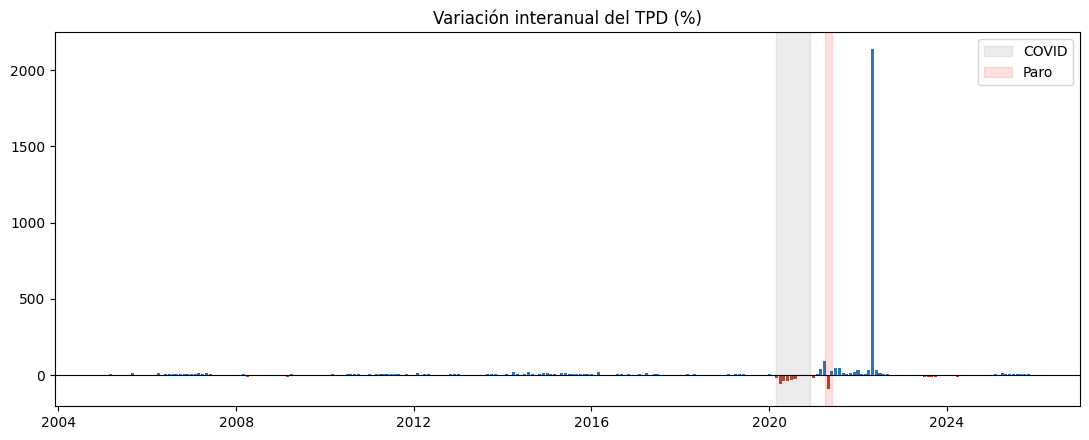

                tpd  yoy_tpd
fecha                       
2020-02-01  32927.3      2.1
2020-03-01  25379.7    -20.7
2020-04-01  15526.4    -55.1
2020-05-01  20369.7    -36.3
2020-06-01  22798.2    -35.0
2020-07-01  25150.0    -28.3
2020-08-01  25762.0    -26.7
2020-09-01  32108.4     -4.3
2020-10-01  35450.1      1.9
2020-11-01  34555.9      1.1
2020-12-01  37018.9     -4.4
2021-01-01  33142.9    -17.1
2021-02-01  34462.0      4.7
2021-03-01  36015.1     41.9
2021-04-01  30200.5     94.5
2021-05-01   1574.7    -92.3
2021-06-01  28394.4     24.5
2021-07-01  36518.4     45.2
Peor mes COVID: 2020-04 (-55.1%)
Primer mes que recupera el nivel del año anterior: 2020-10


In [11]:
# ===== 1. COVID y paro: variación interanual =====
m["yoy_tpd"] = m["tpd"].pct_change(12) * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(m.index, m["yoy_tpd"], width=25, color=np.where(m["yoy_tpd"] >= 0, "#2e75b6", "#c0392b"))
ax.axhline(0, color="black", lw=.8)
ax.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15, label="COVID")
ax.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12, label="Paro")
ax.set_title("Variación interanual del TPD (%)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_yoy_tpd.png", dpi=130); plt.show()

print(m.loc["2020-02":"2021-07", ["tpd", "yoy_tpd"]].round(1).to_string())
caida = m.loc["2020-03":"2020-12", "yoy_tpd"]
print("Peor mes COVID:", caida.idxmin().strftime("%Y-%m"), f"({caida.min():.1f}%)")
post = m.loc["2020-05":"2021-12", "yoy_tpd"]
print("Primer mes que recupera el nivel del año anterior:", post[post >= 0].index[0].strftime("%Y-%m"))

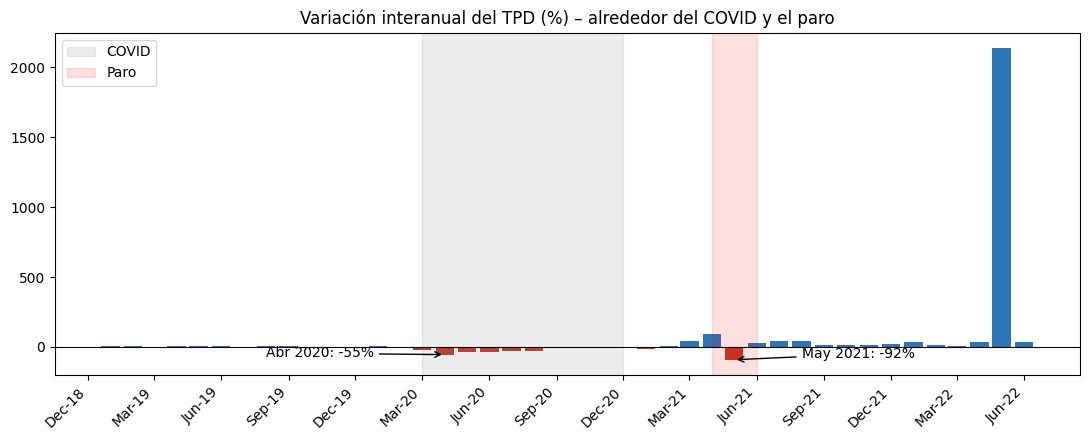

In [12]:
import matplotlib.dates as mdates

v = m.loc["2019-01":"2022-06"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(v.index, v["yoy_tpd"], width=25, color=np.where(v["yoy_tpd"] >= 0, "#2e75b6", "#c0392b"))
ax.axhline(0, color="black", lw=.8)
ax.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15, label="COVID")
ax.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12, label="Paro")
ax.annotate("Abr 2020: -55%", xy=(pd.Timestamp("2020-04-01"), -55), xytext=(pd.Timestamp("2019-08-01"), -75),
            arrowprops=dict(arrowstyle="->"))
ax.annotate("May 2021: -92%", xy=(pd.Timestamp("2021-05-01"), -92), xytext=(pd.Timestamp("2021-08-01"), -80),
            arrowprops=dict(arrowstyle="->"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("Variación interanual del TPD (%) – alrededor del COVID y el paro")
ax.legend(); plt.tight_layout(); plt.show()

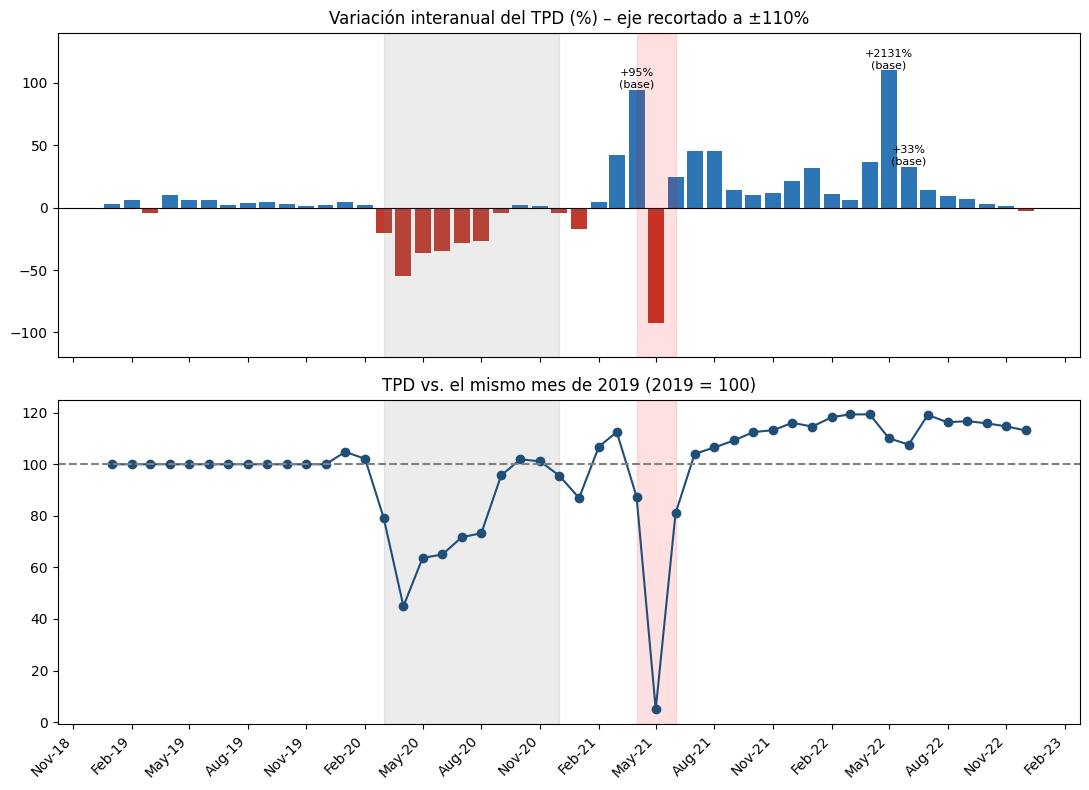

In [13]:
import matplotlib.dates as mdates

v = m.loc["2019-01":"2022-12"].copy()
base2019 = m.loc["2019"].set_index(m.loc["2019"].index.month)["tpd"]
v["idx_vs_2019"] = v["tpd"] / v.index.month.map(base2019).values * 100

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
ax[0].bar(v.index, v["yoy_tpd"].clip(-110, 110), width=25, color=np.where(v["yoy_tpd"] >= 0, "#2e75b6", "#c0392b"))
ax[0].axhline(0, color="black", lw=.8)
for f, txt in [("2021-04-01", "+95%\n(base)"), ("2022-05-01", "+2131%\n(base)"), ("2022-06-01", "+33%\n(base)")]:
    ax[0].annotate(txt, (pd.Timestamp(f), min(v.loc[f, "yoy_tpd"], 110)), ha="center", va="bottom", fontsize=8)
ax[0].set_ylim(-120, 140); ax[0].set_title("Variación interanual del TPD (%) – eje recortado a ±110%")

ax[1].plot(v.index, v["idx_vs_2019"], marker="o", color="#1f4e79")
ax[1].axhline(100, color="grey", ls="--"); ax[1].set_title("TPD vs. el mismo mes de 2019 (2019 = 100)")

for a in ax:
    a.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15)
    a.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12)
ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax[1].get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

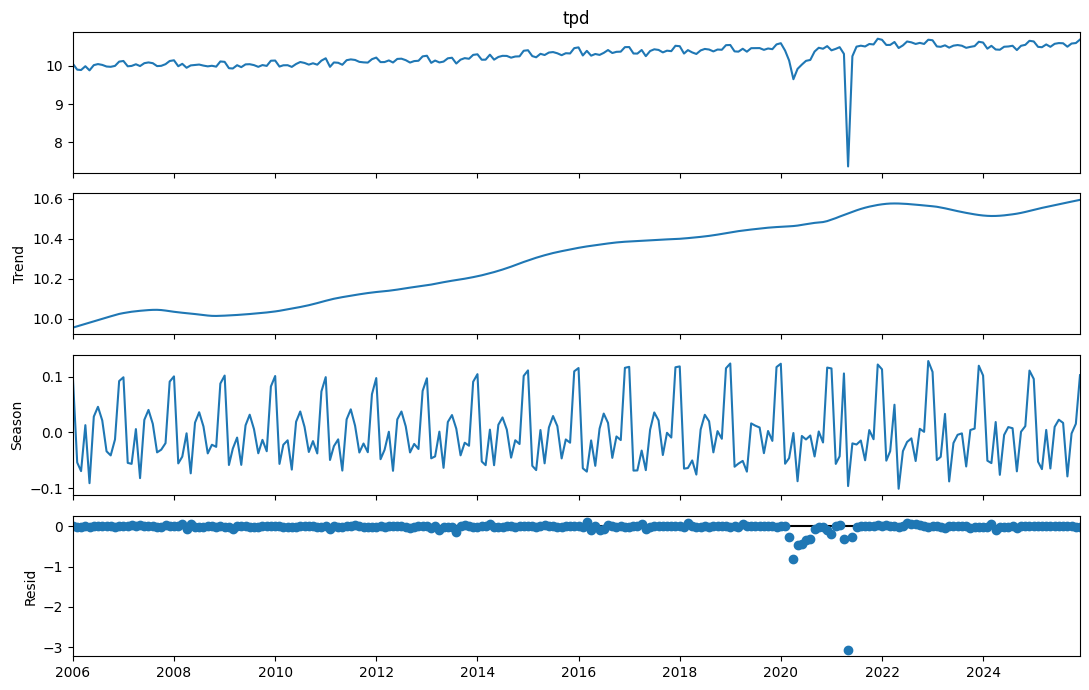

Meses atípicos: ['2020-04', '2021-05']


In [14]:
# ===== 2. Descomposición STL =====
if HAS_SM:
    stl = STL(np.log(m.loc["2006":, "tpd"]), period=12, robust=True).fit()
    fig = stl.plot(); fig.set_size_inches(11, 7); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/fig_stl.png", dpi=130); plt.show()
    res = stl.resid
    atip = res[abs(res) > 2.5 * res.std()]
    print("Meses atípicos:", [d.strftime("%Y-%m") for d in atip.index])
else:
    print("STL omitida (statsmodels no disponible).")

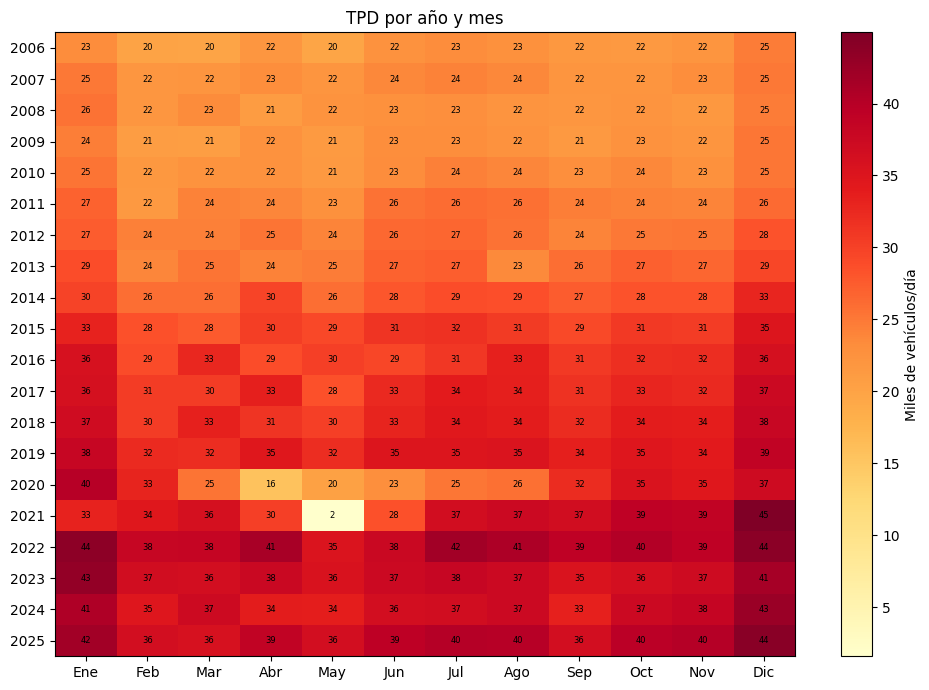

In [15]:
# ===== 3. Mapa de calor año × mes =====
hm = (m.loc["2006":"2025"]
        .assign(anio=lambda x: x.index.year, mes=lambda x: x.index.month)
        .pivot(index="anio", columns="mes", values="tpd") / 1e3)
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(hm.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(12)); ax.set_xticklabels(["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"])
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:.0f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, label="Miles de vehículos/día"); ax.set_title("TPD por año y mes")
plt.tight_layout(); plt.show()

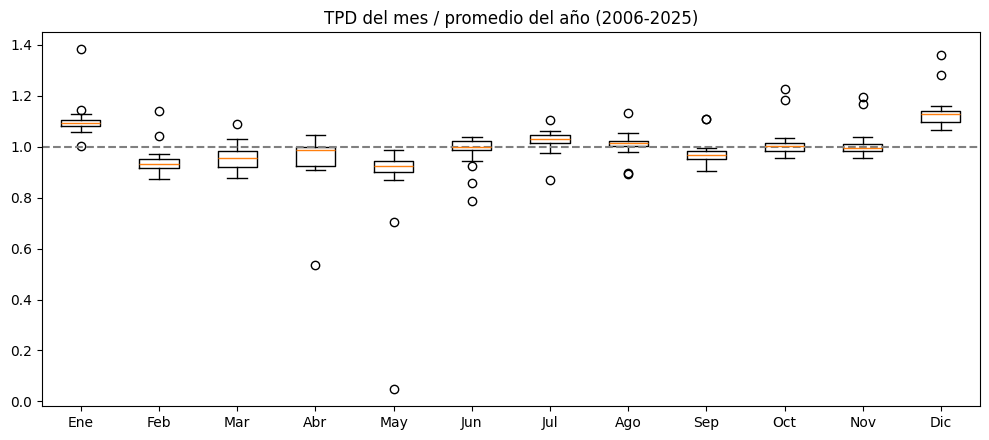

In [16]:
# ===== 4. Estacionalidad (2006-2025) =====
z = m.loc["2006":"2025", "tpd"]
rel = z / z.groupby(z.index.year).transform("mean")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([rel[rel.index.month == k] for k in range(1, 13)])
ax.set_xticklabels(["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"])
ax.axhline(1, color="grey", ls="--"); ax.set_title("TPD del mes / promedio del año (2006-2025)")
plt.tight_layout(); plt.show()

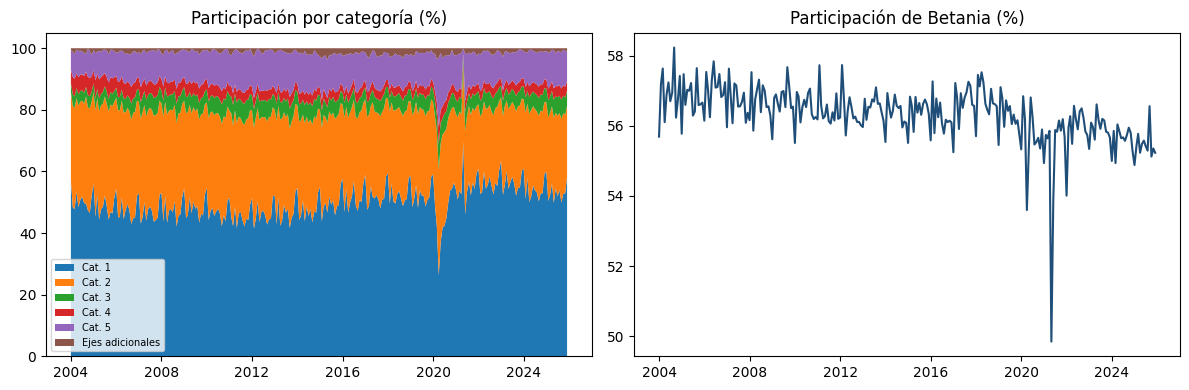

In [17]:
# ===== 5. Composición del tráfico (categorías y estaciones) =====
# >>> MODIFICADO: ya no hay livianos/pesados; se usa la composición por categoría (Cat. 1-5 + ejes adicionales)
partes = {f"Cat. {c}": m[f"trafico_betania_cat{c}"] + m[f"trafico_uribe_cat{c}"] for c in range(1, 6)}
partes["Ejes adicionales"] = m["trafico_betania_ea"] + m["trafico_uribe_ea"]
share = pd.DataFrame(partes).div(m["trafico_total"], axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].stackplot(share.index, *[share[c] for c in share.columns], labels=share.columns)
ax[0].set_title("Participación por categoría (%)"); ax[0].legend(loc="lower left", fontsize=7)
ax[1].plot(m.index, m["trafico_betania"] / m["trafico_total"] * 100, color="#1f4e79")
ax[1].set_title("Participación de Betania (%)")
plt.tight_layout(); plt.show()

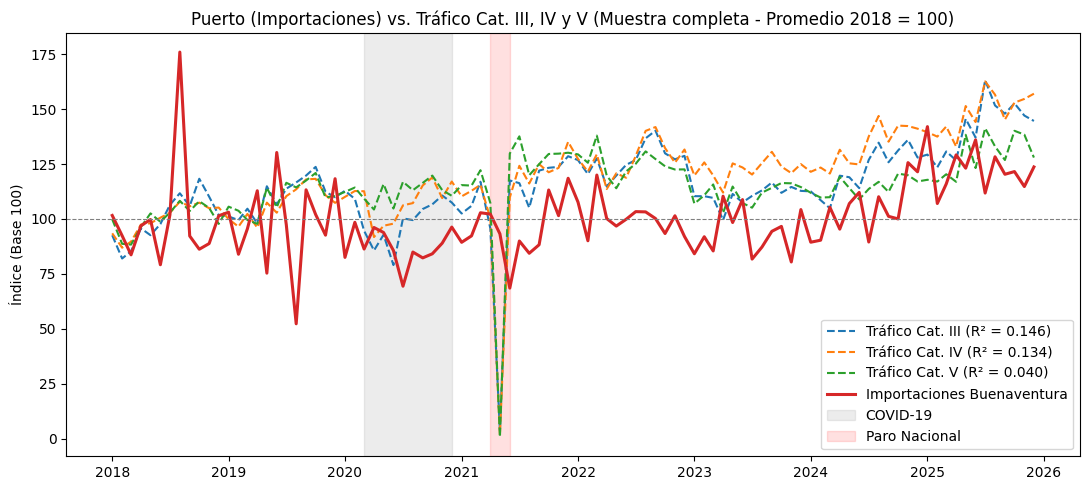

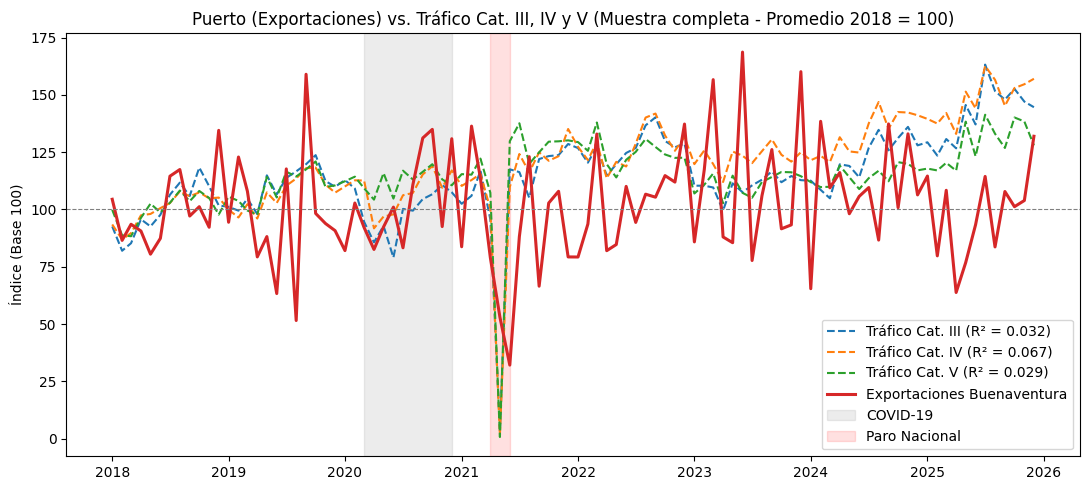

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Cálculo de variables agregadas por categoría (Betania + Uribe)
m["trafico_cat3"] = m["trafico_betania_cat3"] + m["trafico_uribe_cat3"]
m["trafico_cat4"] = m["trafico_betania_cat4"] + m["trafico_uribe_cat4"]
m["trafico_cat5"] = m["trafico_betania_cat5"] + m["trafico_uribe_cat5"]

# Tomar los datos completos del puerto (con COVID y Paro incluidos)
p_imp = m.dropna(subset=["port_import"])[["trafico_cat3", "trafico_cat4", "trafico_cat5", "port_import"]]
p_exp = m.dropna(subset=["port_export"])[["trafico_cat3", "trafico_cat4", "trafico_cat5", "port_export"]]

# Nombres amigables para las leyendas
nombres_imp = {
    "trafico_cat3": "Tráfico Cat. III",
    "trafico_cat4": "Tráfico Cat. IV",
    "trafico_cat5": "Tráfico Cat. V",
    "port_import": "Importaciones Buenaventura"
}

nombres_exp = {
    "trafico_cat3": "Tráfico Cat. III",
    "trafico_cat4": "Tráfico Cat. IV",
    "trafico_cat5": "Tráfico Cat. V",
    "port_export": "Exportaciones Buenaventura"
}

# Conversión a índice base 100 (Promedio 2018 = 100)
idx100_imp = p_imp.div(p_imp.iloc[:12].mean()) * 100
idx100_exp = p_exp.div(p_exp.iloc[:12].mean()) * 100

# Gráfico 1: Importaciones vs Categorías III, IV, V (con R² calculado sobre toda la serie)
fig1, ax1 = plt.subplots(figsize=(11, 5))
for col in idx100_imp.columns:
    es_puerto = (col == "port_import")
    label_txt = nombres_imp[col]
    if not es_puerto:
        # Calcular R² de la categoría con respecto a importaciones con datos completos
        r2 = idx100_imp[col].corr(idx100_imp["port_import"]) ** 2
        label_txt += f" (R² = {r2:.3f})"
    ax1.plot(idx100_imp.index, idx100_imp[col], label=label_txt,
             linewidth=2.2 if es_puerto else 1.5,
             linestyle="-" if es_puerto else "--")
ax1.axhline(100, color="grey", ls="--", lw=.8)
# Agregar sombreado de COVID y Paro
ax1.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15, label="COVID-19")
ax1.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12, label="Paro Nacional")
ax1.set_title("Puerto (Importaciones) vs. Tráfico Cat. III, IV y V (Muestra completa - Promedio 2018 = 100)")
ax1.set_ylabel("Índice (Base 100)")
ax1.legend()
plt.tight_layout()
plt.show()

# Gráfico 2: Exportaciones vs Categorías III, IV, V (con R² calculado sobre toda la serie)
fig2, ax2 = plt.subplots(figsize=(11, 5))
for col in idx100_exp.columns:
    es_puerto = (col == "port_export")
    label_txt = nombres_exp[col]
    if not es_puerto:
        # Calcular R² de la categoría con respecto a exportaciones con datos completos
        r2 = idx100_exp[col].corr(idx100_exp["port_export"]) ** 2
        label_txt += f" (R² = {r2:.3f})"
    ax2.plot(idx100_exp.index, idx100_exp[col], label=label_txt,
             linewidth=2.2 if es_puerto else 1.5,
             linestyle="-" if es_puerto else "--")
ax2.axhline(100, color="grey", ls="--", lw=.8)
# Agregar sombreado de COVID y Paro
ax2.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15, label="COVID-19")
ax2.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12, label="Paro Nacional")
ax2.set_title("Puerto (Exportaciones) vs. Tráfico Cat. III, IV y V (Muestra completa - Promedio 2018 = 100)")
ax2.set_ylabel("Índice (Base 100)")
ax2.legend()
plt.tight_layout()
plt.show()

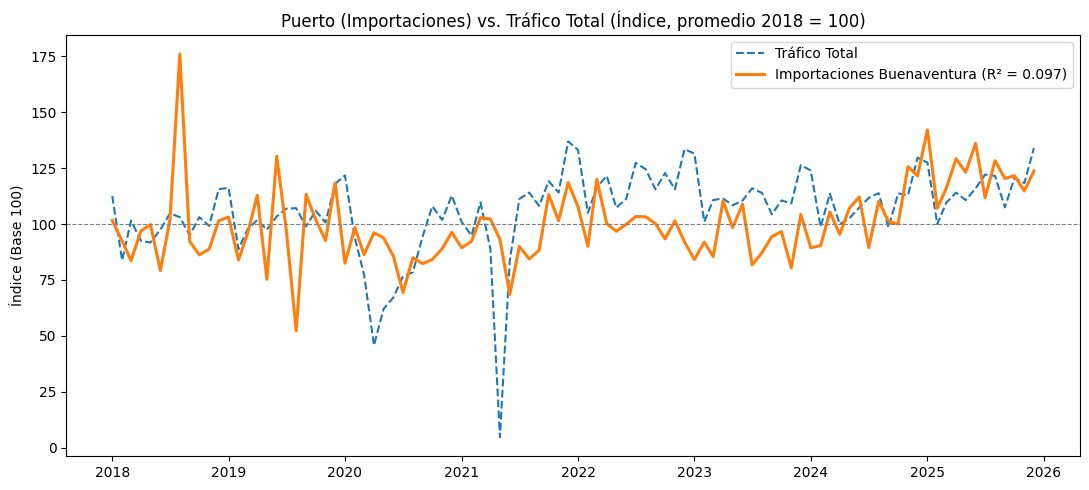

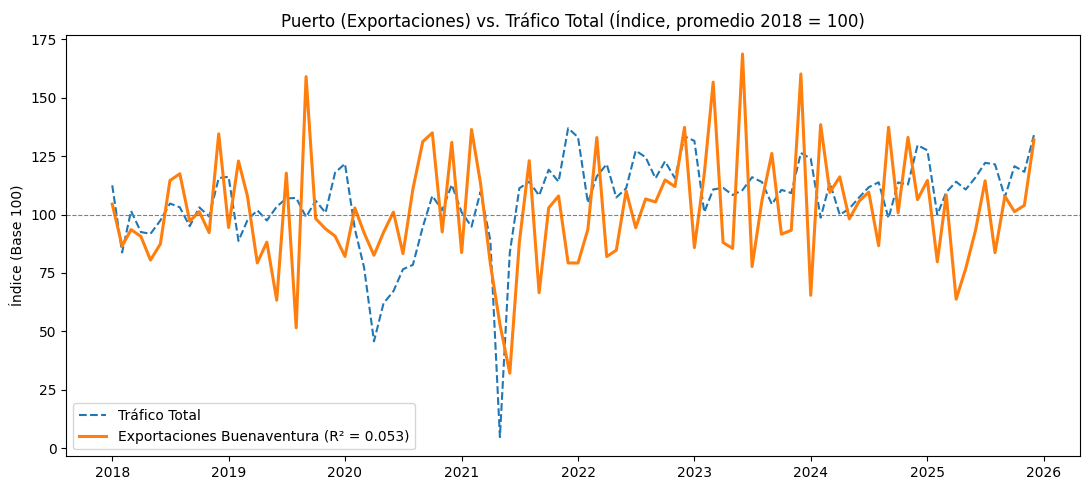

In [19]:
# Filtrar datos de puerto e incluir las variables solicitadas (Tráfico Total e Importación/Exportación)
p_imp = m.dropna(subset=["port_import"])[["trafico_total", "port_import"]]
p_exp = m.dropna(subset=["port_export"])[["trafico_total", "port_export"]]

# Nombres amigables para las leyendas
nombres_imp = {
    "trafico_total": "Tráfico Total",
    "port_import": "Importaciones Buenaventura"
}

nombres_exp = {
    "trafico_total": "Tráfico Total",
    "port_export": "Exportaciones Buenaventura"
}

# Conversión a índice base 100 (Promedio 2018 = 100)
idx100_imp = p_imp.div(p_imp.iloc[:12].mean()) * 100
idx100_exp = p_exp.div(p_exp.iloc[:12].mean()) * 100

# Cálculo del coeficiente de determinación R^2 (Pearson r al cuadrado)
r2_imp = idx100_imp["port_import"].corr(idx100_imp["trafico_total"]) ** 2
r2_exp = idx100_exp["port_export"].corr(idx100_exp["trafico_total"]) ** 2

# Gráfico 1: Solo Importaciones vs Tráfico Total (con R^2)
fig1, ax1 = plt.subplots(figsize=(11, 5))
for col in idx100_imp.columns:
    es_puerto = (col == "port_import")
    label_txt = nombres_imp[col]
    if es_puerto:
        label_txt += f" (R² = {r2_imp:.3f})"
    ax1.plot(idx100_imp.index, idx100_imp[col], label=label_txt,
             linewidth=2.2 if es_puerto else 1.5,
             linestyle="-" if es_puerto else "--")
ax1.axhline(100, color="grey", ls="--", lw=.8)
ax1.set_title("Puerto (Importaciones) vs. Tráfico Total (Índice, promedio 2018 = 100)")
ax1.set_ylabel("Índice (Base 100)")
ax1.legend()
plt.tight_layout()
plt.show()

# Gráfico 2: Solo Exportaciones vs Tráfico Total (con R^2)
fig2, ax2 = plt.subplots(figsize=(11, 5))
for col in idx100_exp.columns:
    es_puerto = (col == "port_export")
    label_txt = nombres_exp[col]
    if es_puerto:
        label_txt += f" (R² = {r2_exp:.3f})"
    ax2.plot(idx100_exp.index, idx100_exp[col], label=label_txt,
             linewidth=2.2 if es_puerto else 1.5,
             linestyle="-" if es_puerto else "--")
ax2.axhline(100, color="grey", ls="--", lw=.8)
ax2.set_title("Puerto (Exportaciones) vs. Tráfico Total (Índice, promedio 2018 = 100)")
ax2.set_ylabel("Índice (Base 100)")
ax2.legend()
plt.tight_layout()
plt.show()

In [20]:
# ¿Aporta información el puerto? Correlación de variaciones interanuales (log) con rezagos
# >>> MODIFICADO: variables del dataset maestro (I+E, importaciones y exportaciones); sin pesados ni contenedores
ex = m.dropna(subset=["port_ie"]).copy()
v = np.log(ex[["trafico_total", "trafico_cat5", "port_ie", "port_import", "port_export"]]).diff(12).dropna()
tabla = pd.DataFrame({f"rezago {L}m": {
    "tráfico total ~ puerto (I+E)": v["trafico_total"].corr(v["port_ie"].shift(L)),
    "Cat. V ~ puerto (I+E)": v["trafico_cat5"].corr(v["port_ie"].shift(L)),
    "Cat. V ~ importaciones": v["trafico_cat5"].corr(v["port_import"].shift(L)),
    "Cat. V ~ exportaciones": v["trafico_cat5"].corr(v["port_export"].shift(L)),
} for L in range(0, 4)}).round(2)
print("Correlación de variaciones anuales (n =", len(v), "meses)")
print(tabla)

Correlación de variaciones anuales (n = 84 meses)
                              rezago 0m  rezago 1m  rezago 2m  rezago 3m
tráfico total ~ puerto (I+E)       0.13       0.05       0.02       0.01
Cat. V ~ puerto (I+E)              0.09      -0.01      -0.00      -0.03
Cat. V ~ importaciones             0.04      -0.00       0.01       0.05
Cat. V ~ exportaciones             0.20      -0.03      -0.04      -0.18


In [21]:
d_ = m.loc["2006":].copy()
d_["tpd_cat5"] = d_["trafico_cat5"] / d_["dias"]
MASCARAS = {"Toda la muestra 2006-2026": np.ones(len(d_), bool),
            "Sin COVID/paro (excl. mar-2020 a dic-2021)": ((d_.index < "2020-03-01") | (d_.index > "2021-12-01")),
            "Solo 2006-2019": (d_.index < "2020-01-01")}
VARS_ISE = {"ISE total": "ise", "ISE comercio-transporte": "ise_comercio_transp", "ISE agricultura": "ise_agricultura"}   # >>> MODIFICADO
OBJ = {"TPD total": "tpd", "TPD Cat. V": "tpd_cat5"}   # >>> MODIFICADO: sin pesados

filas_corr = []
for nom_m, mask in MASCARAS.items():
    for nom_o, col_o in OBJ.items():
        y_ = np.log(d_[col_o]).diff(12)
        for nom_v, col_v in VARS_ISE.items():
            x_ = np.log(d_[col_v]).diff(12)
            for L in (0, 1, 2, 3, 6):
                z_ = pd.concat([y_, x_.shift(L)], axis=1)[mask].dropna()
                filas_corr.append((nom_m, nom_o, nom_v, L, z_.iloc[:, 0].corr(z_.iloc[:, 1]), len(z_)))
corr_ise = pd.DataFrame(filas_corr, columns=["muestra", "objetivo", "variable", "rezago_m", "corr", "n"])
corr_ise.to_csv(f"{OUT_DIR}/corr_ise_trafico.csv", index=False)

for nom_m in MASCARAS:
    t_ = corr_ise[(corr_ise["muestra"] == nom_m) & (corr_ise["objetivo"] == "TPD total")]
    print(f"\n{nom_m}  (correlación de variaciones anuales con TPD total)")
    print(t_.pivot(index="variable", columns="rezago_m", values="corr").round(2).to_string())


Toda la muestra 2006-2026  (correlación de variaciones anuales con TPD total)
rezago_m                    0     1     2     3     6
variable                                             
ISE agricultura          0.22 -0.01 -0.06  0.12  0.12
ISE comercio-transporte  0.35  0.18  0.17  0.24  0.13
ISE total                0.36  0.16  0.16  0.25  0.16

Sin COVID/paro (excl. mar-2020 a dic-2021)  (correlación de variaciones anuales con TPD total)
rezago_m                    0     1     2     3     6
variable                                             
ISE agricultura          0.06 -0.05 -0.10 -0.02  0.12
ISE comercio-transporte  0.53  0.45  0.27  0.22  0.27
ISE total                0.43  0.33  0.20  0.18  0.25

Solo 2006-2019  (correlación de variaciones anuales con TPD total)
rezago_m                    0     1     2     3     6
variable                                             
ISE agricultura         -0.15  0.06 -0.00 -0.04  0.02
ISE comercio-transporte  0.31  0.31  0.23  0.16  0.11
I

###3.4 Análisis de correlación con el ISE

Se comparan variaciones anuales (log) del tráfico contra variaciones anuales del ISE con rezagos de 0 a 6 meses. Para evitar que el COVID y el paro dominen la correlación, se reporta (a) toda la muestra, (b) excluyendo marzo-2020 a diciembre-2021 y (c) solo 2006-2019.

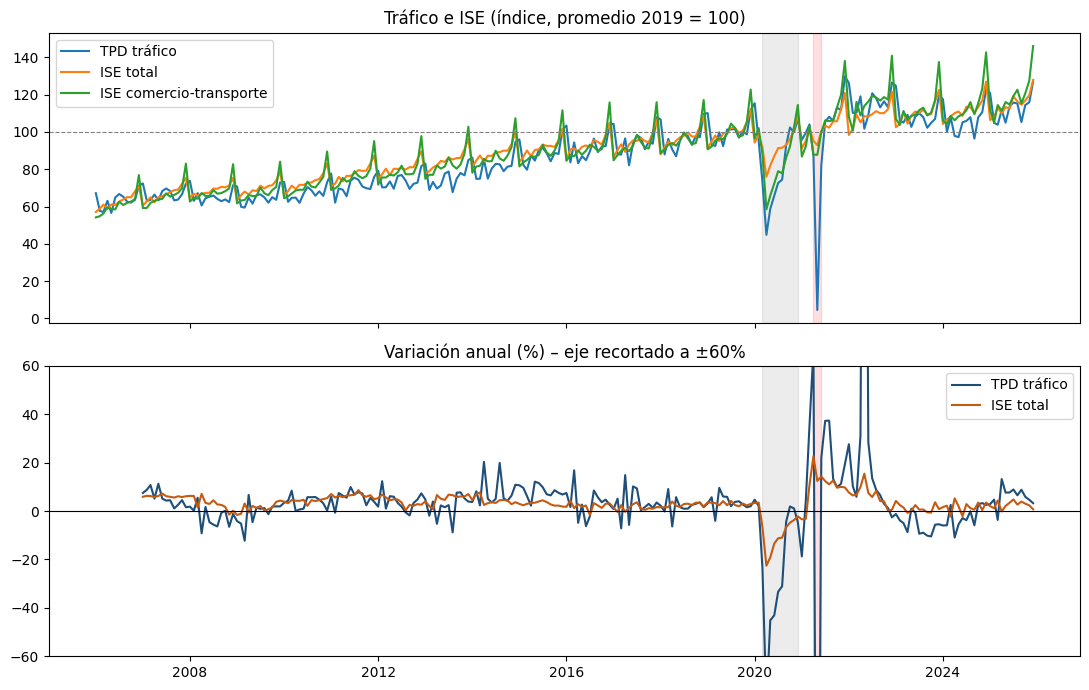

In [22]:
z = m.loc["2006":, ["tpd", "ise", "ise_comercio_transp"]].dropna()
base = z.loc["2019"].mean()
yo = np.log(z).diff(12) * 100
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for c, nom in [("tpd", "TPD tráfico"), ("ise", "ISE total"), ("ise_comercio_transp", "ISE comercio-transporte")]:
    ax[0].plot(z.index, z[c] / base[c] * 100, label=nom)
ax[0].axhline(100, color="grey", ls="--", lw=.8); ax[0].legend(); ax[0].set_title("Tráfico e ISE (índice, promedio 2019 = 100)")
ax[1].plot(yo.index, yo["tpd"], label="TPD tráfico", color="#1f4e79")
ax[1].plot(yo.index, yo["ise"], label="ISE total", color="#c55a11")
ax[1].set_ylim(-60, 60); ax[1].axhline(0, color="black", lw=.8); ax[1].legend()
ax[1].set_title("Variación anual (%) – eje recortado a ±60%")
for a in ax:
    a.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15)
    a.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_ise_vs_trafico.png", dpi=130); plt.show()

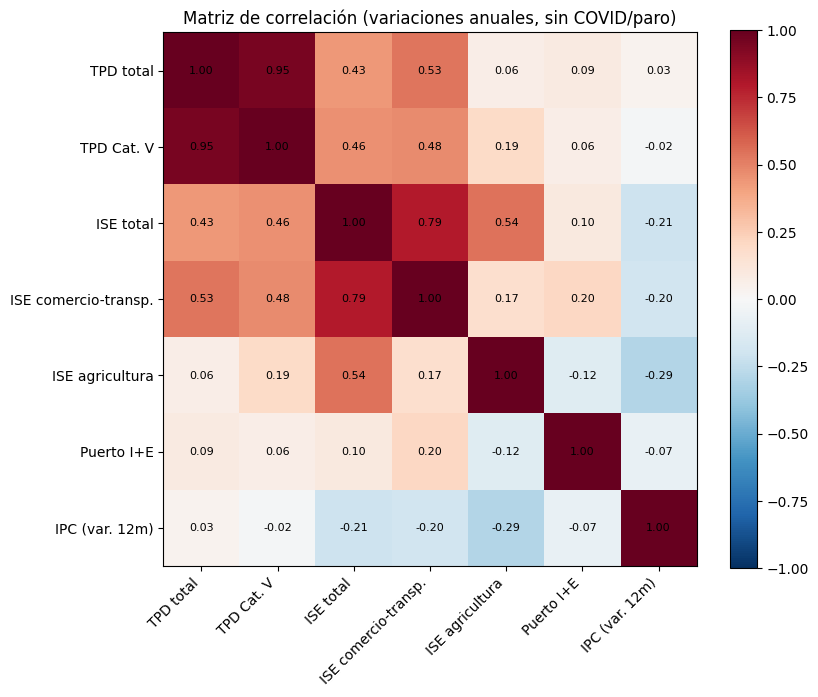

In [24]:
mm = m.loc["2006":].copy()
mm["tarifa_real_yoy"] = np.log(mm["tarifa_cat1_real"]).diff(12)
yo = pd.DataFrame({
    "TPD total": np.log(mm["tpd"]).diff(12),
    "TPD Cat. V": np.log(mm["trafico_cat5"] / mm["dias"]).diff(12),
    "ISE total": np.log(mm["ise"]).diff(12),
    "ISE comercio-transp.": np.log(mm["ise_comercio_transp"]).diff(12),
    "ISE agricultura": np.log(mm["ise_agricultura"]).diff(12),
    "Puerto I+E": np.log(mm["port_ie"]).diff(12),
    "IPC (var. 12m)": mm["ipc_var12"],
})
fuera = ~(((mm.index >= "2020-03-01") & (mm.index <= "2021-12-01")))
cm = yo[fuera].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=45, ha="right")
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.set_title("Matriz de correlación (variaciones anuales, sin COVID/paro)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_matriz_correlacion.png", dpi=130); plt.show()
cm.round(2).to_csv(f"{OUT_DIR}/matriz_correlacion.csv")

### 3.5 Definición de la variable objetivo, del horizonte y partición temporal
**Estrategia de pronóstico directo a 12 meses.** Para cada fecha de corte *t* y cada horizonte *h* = 1…12 se predice el **crecimiento interanual del TMD** (log TPD(t+h) − log TPD(t+h−12)) con información disponible hasta *t*. Así el modelo ya queda "desestacionalizado" y sin tendencia, y se evita acumular errores recursivos.

Conjuntos de variables (ablación para medir qué aporta cada bloque):
- **A_base**: crecimiento reciente (1, 3, 6, 12 m), mes, calendario (festivos, fines de semana, Semana Santa), COVID/paro.
- **B_macro**: A + IPC (var. 12m) y variación real de la tarifa Cat. I.
- **C_puerto**: B + variación interanual (media 3 meses) de la carga del puerto de Buenaventura (importaciones + exportaciones), con 2 meses de rezago de publicación.
- **D_ise**: B + variación interanual (media 3 meses) del **ISE total**, con 2 meses de rezago de publicación.
- **E_ise_sector**: B + variación interanual (media 3 meses) del **ISE de comercio-transporte**, con 2 meses de rezago.

In [25]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

H = 12                  # horizonte (meses)
LAG_PUERTO = 2          # meses de rezago con que se conoce el dato portuario
LAG_ISE = 2             # el DANE publica el ISE ~7 semanas después del cierre del mes → 2 meses de rezago
SEED = 42

d = m.loc[VENTANA_INICIO:].copy()
N = len(d)
y = np.log(d["tpd"].values)                                   # variable que se modela: log(TMD)

idx_ext = pd.date_range(d.index[0], periods=N + H + 6, freq="MS")   # calendario también hacia el futuro
cal = calendario(idx_ext).join(eventos(idx_ext))
fest, findes, ss, cov, paro, dias = (cal[c].values for c in
                                     ["n_festivos", "n_findes", "semana_santa", "covid", "paro", "dias"])
mes = cal.index.month.values
ipc12 = d["ipc_var12"].values
tar_real = d["tarifa_cat1_real"].values
port_tot = d["port_ie"].values                              # I+E del puerto (NaN antes de 2018)   >>> MODIFICADO
ise_v = d["ise"].values
ise_ct = d["ise_comercio_transp"].values

def construir_filas():
    filas = []
    for t in range(23, N):
        g = {"g1": y[t] - y[t - 12]}
        for k in (3, 6, 12):
            g[f"g{k}"] = y[t - k + 1:t + 1].mean() - y[t - 12 - k + 1:t - 12 + 1].mean()
        g["ipc_var12"] = ipc12[t]
        g["tarifa_real_yoy"] = np.log(tar_real[t] / tar_real[t - 12])
        tp = t - LAG_PUERTO
        a, b0 = port_tot[tp - 2:tp + 1].mean(), port_tot[tp - 14:tp - 11].mean()
        g["port_yoy3"] = np.log(a / b0) if (a > 0 and b0 > 0) else np.nan
        ti = t - LAG_ISE
        g["ise_yoy3"] = np.log(ise_v[ti - 2:ti + 1].mean() / ise_v[ti - 14:ti - 11].mean())
        g["ise_ct_yoy3"] = np.log(ise_ct[ti - 2:ti + 1].mean() / ise_ct[ti - 14:ti - 11].mean())
        for h in range(1, H + 1):
            s, b = t + h, t + h - 12
            f = dict(t=t, h=h, s=s, y_base=y[b], **g,
                     d_fest=fest[s] - fest[b], d_findes=findes[s] - findes[b], d_ss=ss[s] - ss[b],
                     tgt_covid=cov[s], tgt_paro=paro[s], base_covid=cov[b], base_paro=paro[b])
            for k in range(2, 13):
                f[f"mes{k}"] = int(mes[s] == k)
            f["z"] = y[s] - y[b] if s < N else np.nan
            filas.append(f)
    return pd.DataFrame(filas)

filas = construir_filas()
BASE = ["g1", "g3", "g6", "g12", "h", "d_fest", "d_findes", "d_ss", "tgt_covid", "tgt_paro",
        "base_covid", "base_paro"] + [f"mes{k}" for k in range(2, 13)]
SETS = {"A_base": BASE,
        "B_macro": BASE + ["ipc_var12", "tarifa_real_yoy"],
        "C_puerto": BASE + ["ipc_var12", "tarifa_real_yoy", "port_yoy3"],
        "D_ise": BASE + ["ipc_var12", "tarifa_real_yoy", "ise_yoy3"],
        "E_ise_sector": BASE + ["ipc_var12", "tarifa_real_yoy", "ise_ct_yoy3"]}
print("Filas (corte × horizonte):", len(filas), "| meses en la ventana:", N)

Filas (corte × horizonte): 2604 | meses en la ventana: 240


## FASE 4 · Modelado  
- **Referencia:** naive estacional (mismo mes del año anterior), solo como punto de comparación del criterio de éxito (no cuenta como modelo; se desactiva con `INCLUIR_NAIVE = False`).
- **Regresión lineal múltiple (MCO):** log(TPD) ~ tendencia + dummies de mes (+ dummies COVID y paro, configurable con `OLS_CON_EVENTOS`).
- **Estadísticos:** SARIMAX (con festivos, Semana Santa, COVID y paro como exógenas) y Holt-Winters (ETS).
- **Machine learning (pronóstico directo):** XGBoost y red neuronal MLP pequeña.

In [28]:
def modelos_ml():
    return {
        "XGBoost": lambda: XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                        objective="reg:squarederror", random_state=SEED, n_jobs=-1),
        "MLP": lambda: make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1e-2,
                                                                    max_iter=3000, random_state=SEED)),
    }

def pred_ml(fabrica, cols, T, exigir=()):
    # 'exigir': columnas que deben existir en el entrenamiento aunque no se usen como variables
    # (sirve para comparar con/sin puerto sobre exactamente la misma muestra)
    tr_ = filas[filas["s"] <= T].dropna(subset=cols + list(exigir) + ["z"])
    te_ = filas[filas["t"] == T].sort_values("h")
    if te_[cols].isna().any().any():
        return None
    mod = fabrica()
    mod.fit(tr_[cols].values, tr_["z"].values)
    return te_["y_base"].values + mod.predict(te_[cols].values)       # log TMD para T+1..T+12

def pred_naive(T):
    return np.array([y[T + h - 12] for h in range(1, H + 1)])

# Regresión lineal múltiple (MCO) con tendencia y dummies de mes sobre log(TPD)
OLS_CON_EVENTOS = True        # True: agrega dummies COVID y paro (coherente con SARIMAX). False: solo tendencia + mes
_cols_ols = [np.ones(len(idx_ext)), np.arange(len(idx_ext), dtype=float)] + [(mes == k).astype(float) for k in range(2, 13)]
if OLS_CON_EVENTOS:
    _cols_ols += [cov.astype(float), paro.astype(float)]
X_OLS = np.column_stack(_cols_ols)

def pred_ols(T):
    beta, *_ = np.linalg.lstsq(X_OLS[:T + 1], y[:T + 1], rcond=None)
    return X_OLS[T + 1:T + 1 + H] @ beta                              # log TMD para T+1..T+12

EXOG = np.column_stack([fest, findes, ss, cov, paro]).astype(float)

if HAS_SM:
    def pred_sarimax(T, order, sorder):
        res = SARIMAX(y[:T + 1], exog=EXOG[:T + 1], order=order, seasonal_order=sorder,
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
        return res.forecast(H, exog=EXOG[T + 1:T + 1 + H])

    def pred_ets(T):
        res = ExponentialSmoothing(y[:T + 1], trend="add", damped_trend=True, seasonal="add",
                                   seasonal_periods=12).fit()
        return res.forecast(H)

# Fechas de corte del backtesting: cada 3 meses, el último con 12 meses completos de real para comparar
ORIGENES = [N - 1 - H - 3 * k for k in range(12)][::-1]
print("Cortes de validación:", d.index[ORIGENES[0]].date(), "→", d.index[ORIGENES[-1]].date(), f"({len(ORIGENES)} cortes × {H} horizontes)")

Cortes de validación: 2022-03-01 → 2024-12-01 (12 cortes × 12 horizontes)


### 4.1 Selección del orden SARIMAX (AIC en el primer corte; se mantiene fijo en el resto)

In [27]:
if HAS_SM:
    T0 = ORIGENES[0]
    t0 = time.time()
    cand = []
    for p, q, dd, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1], [0, 1]):
        try:
            r = SARIMAX(y[:T0 + 1], exog=EXOG[:T0 + 1], order=(p, dd, q), seasonal_order=(P, 1, Q, 12),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
            cand.append(((p, dd, q), (P, 1, Q, 12), r.aic))
        except Exception:
            pass
    cand = sorted(cand, key=lambda c: c[2])
    ORD, SORD, _ = cand[0]
    print("Mejores órdenes por AIC:"); [print("  ", c) for c in cand[:3]]
    print(f"→ SARIMAX{ORD}x{SORD}  ({time.time() - t0:.0f}s)")
else:
    print("SARIMAX omitido (statsmodels no disponible).")

Mejores órdenes por AIC:
   ((2, 1, 1), (1, 1, 1, 12), np.float64(-114.5205413366171))
   ((2, 1, 1), (1, 1, 0, 12), np.float64(-111.00869231954792))
   ((1, 1, 1), (1, 1, 1, 12), np.float64(-109.72331551309972))
→ SARIMAX(2, 1, 1)x(1, 1, 1, 12)  (47s)


### 4.2 Entrenamiento con origen móvil (backtesting)
Para cada corte se entrena **solo con datos hasta ese mes** y se pronostican los 12 meses siguientes. Métricas sobre el **tráfico mensual total** (vehículos): MAE, RMSE y MAPE.

In [29]:
INCLUIR_NAIVE = True      # el naive estacional es la referencia del criterio de éxito 1; no entra al ensamble
MODELOS = {"Naive estacional": pred_naive} if INCLUIR_NAIVE else {}
MODELOS["Regresión lineal MCO (tendencia + mes)"] = pred_ols                   # >>> NUEVO
if HAS_SM:
    MODELOS.update({"SARIMAX (orden por AIC + exógenas)": lambda T: pred_sarimax(T, ORD, SORD),
                    "Holt-Winters (ETS)": pred_ets})
# Conjuntos de variables. "B_misma_muestra" = B_macro entrenado SOLO con las filas donde hay dato de puerto:
# es el control justo para C_puerto (mismo tamaño de muestra, con y sin la variable del puerto).
CONJUNTOS = {"A_base": (SETS["A_base"], ()), "B_macro": (SETS["B_macro"], ()),
             "B_misma_muestra": (SETS["B_macro"], ("port_yoy3",)), "C_puerto": (SETS["C_puerto"], ()),
             "D_ise": (SETS["D_ise"], ()), "E_ise_sector": (SETS["E_ise_sector"], ())}
for algo, fab in modelos_ml().items():
    for nombre_set, (cols, exig) in CONJUNTOS.items():
        MODELOS[f"{algo} [{nombre_set}]"] = (lambda fab, cols, exig: (lambda T: pred_ml(fab, cols, T, exig)))(fab, cols, exig)

registros = []
t0 = time.time()
for nombre, fn in MODELOS.items():
    for T in ORIGENES:
        yh = fn(T)
        if yh is None:
            continue
        pred = np.exp(yh) * dias[T + 1:T + 1 + H]
        real = d["trafico_total"].values[T + 1:T + 1 + H]
        for h in range(H):
            registros.append((nombre, d.index[T], h + 1, d.index[T + 1 + h], real[h], pred[h]))
    print(f"{nombre:<40s} listo  ({time.time() - t0:.0f}s acumulados)")

bt = pd.DataFrame(registros, columns=["modelo", "corte", "h", "fecha", "real", "pred"])

Naive estacional                         listo  (0s acumulados)
Regresión lineal MCO (tendencia + mes)   listo  (0s acumulados)
SARIMAX (orden por AIC + exógenas)       listo  (30s acumulados)
Holt-Winters (ETS)                       listo  (31s acumulados)
XGBoost [A_base]                         listo  (32s acumulados)
XGBoost [B_macro]                        listo  (33s acumulados)
XGBoost [B_misma_muestra]                listo  (35s acumulados)
XGBoost [C_puerto]                       listo  (36s acumulados)
XGBoost [D_ise]                          listo  (37s acumulados)
XGBoost [E_ise_sector]                   listo  (38s acumulados)
MLP [A_base]                             listo  (41s acumulados)
MLP [B_macro]                            listo  (44s acumulados)
MLP [B_misma_muestra]                    listo  (45s acumulados)
MLP [C_puerto]                           listo  (47s acumulados)
MLP [D_ise]                              listo  (50s acumulados)
MLP [E_ise_sector]         

## FASE 5 · Evaluación y resultados


### 5.1 Selección del ensamble sin sesgo optimista

In [30]:
def mape(g): return (abs(g["pred"] - g["real"]) / g["real"]).mean() * 100

ult_sel = d.index[ORIGENES[5] + H]            # >>> NUEVO: último mes objetivo de la ventana de selección
print("Ventana de selección: metas hasta", ult_sel.date(), "| validación (holdout): metas desde",
      (ult_sel + pd.offsets.MonthBegin(1)).date(), "hasta", d.index[-1].date())

cand_ens = [n for n in bt["modelo"].unique() if "misma_muestra" not in n and n != "Naive estacional"]   # >>> MODIFICADO: el naive es referencia, no candidato
rank_sel = (bt[(bt["fecha"] <= ult_sel) & bt["modelo"].isin(cand_ens)]
            .groupby("modelo").apply(mape).sort_values())
top3 = rank_sel.index[:3].tolist()
print("Top-3 elegidos SOLO con la ventana de selección:", top3)

ens = bt[bt["modelo"].isin(top3)].groupby(["corte", "h", "fecha", "real"], as_index=False)["pred"].mean()
ens["modelo"] = "Ensamble top-3"
bt = pd.concat([bt, ens[bt.columns]], ignore_index=True)

bt["err"] = bt["pred"] - bt["real"]
bt["ape"] = bt["err"].abs() / bt["real"]
def resumen(g):
    return pd.Series({
        "MAE": g["err"].abs().mean(), "RMSE": np.sqrt((g["err"] ** 2).mean()), "MAPE_%": g["ape"].mean() * 100,
        "MAPE_h1-3_%": g.loc[g["h"] <= 3, "ape"].mean() * 100,
        "MAPE_h4-6_%": g.loc[g["h"].between(4, 6), "ape"].mean() * 100,
        "MAPE_h7-12_%": g.loc[g["h"] >= 7, "ape"].mean() * 100})

Ventana de selección: metas hasta 2024-06-01 | validación (holdout): metas desde 2024-07-01 hasta 2025-12-01
Top-3 elegidos SOLO con la ventana de selección: ['Holt-Winters (ETS)', 'Regresión lineal MCO (tendencia + mes)', 'XGBoost [D_ise]']


### 5.2 Métricas del backtesting completo y de la ventana de validación (holdout)

In [31]:
metricas = bt.groupby("modelo").apply(resumen).sort_values("MAPE_%").round(2)
metricas.to_csv(f"{OUT_DIR}/metricas_modelos.csv")
print("=== Backtesting completo (12 cortes × 12 horizontes) ===")
print(metricas.to_string())

hold = bt[bt["fecha"] > ult_sel]
metricas_hold = hold.groupby("modelo").apply(resumen).sort_values("MAPE_%").round(2)
if "Naive estacional" in metricas_hold.index:                       # >>> MODIFICADO: solo si el naive está activo
    n_naive = metricas_hold.loc["Naive estacional", "MAPE_%"]
    metricas_hold["MAPE_vs_naive"] = (metricas_hold["MAPE_%"] / n_naive).round(2)
metricas_hold.to_csv(f"{OUT_DIR}/metricas_holdout.csv")        # >>> MODIFICADO: se guarda después de agregar MAPE_vs_naive
print(f"\n=== Ventana de validación (holdout): {hold['fecha'].min().date()} → {hold['fecha'].max().date()}, "
      f"{len(hold[hold['modelo'] == 'Naive estacional'])} pares corte-horizonte ===")
print(metricas_hold.to_string())
print("\nTop-3 usados en el ensamble:", top3)

=== Backtesting completo (12 cortes × 12 horizontes) ===
                                              MAE        RMSE  MAPE_%  MAPE_h1-3_%  MAPE_h4-6_%  MAPE_h7-12_%
modelo                                                                                                       
Ensamble top-3                           65770.62    95130.84    5.81         7.52         5.31          5.20
Naive estacional                         72504.05   118651.80    6.35         8.86         5.53          5.51
Holt-Winters (ETS)                       78034.46   128346.27    6.84         9.59         6.38          5.68
XGBoost [D_ise]                          83144.71   128601.98    7.27         8.47         6.10          7.25
XGBoost [E_ise_sector]                   83643.37   129494.04    7.31         8.54         6.05          7.33
XGBoost [B_macro]                        84764.67   130396.91    7.39         8.41         6.06          7.55
XGBoost [A_base]                         91373.48   133275.80  

### 5.3 Aporte de las variables externas: puerto e ISE (ablación). Se amplía con D_ise y E_ise_sector y se agrega una prueba pareada contra B_macro.

MAPE (%) según variables incluidas (backtesting completo):
set        A_base  B_macro  B_misma_muestra  C_puerto  D_ise  E_ise_sector
algoritmo                                                                 
MLP         17.56    18.13            56.73     41.17  16.21         16.50
XGBoost      7.98     7.39             9.80      9.76   7.27          7.31

MAPE (%) según variables incluidas (solo ventana de validación):
set        A_base  B_macro  B_misma_muestra  C_puerto  D_ise  E_ise_sector
algoritmo                                                                 
MLP          4.33     8.68            12.63     24.18   7.92          8.07
XGBoost      3.82     3.65             4.85      4.87   3.66          3.74

Prueba pareada (dif_MAPE_pp < 0 = mejora al agregar la variable; los pares no son independientes, es indicativa):
algoritmo                 comparación  n_pares  dif_MAPE_pp  % pares donde mejora
  XGBoost C_puerto vs B_misma_muestra    144.0        -0.04                 53

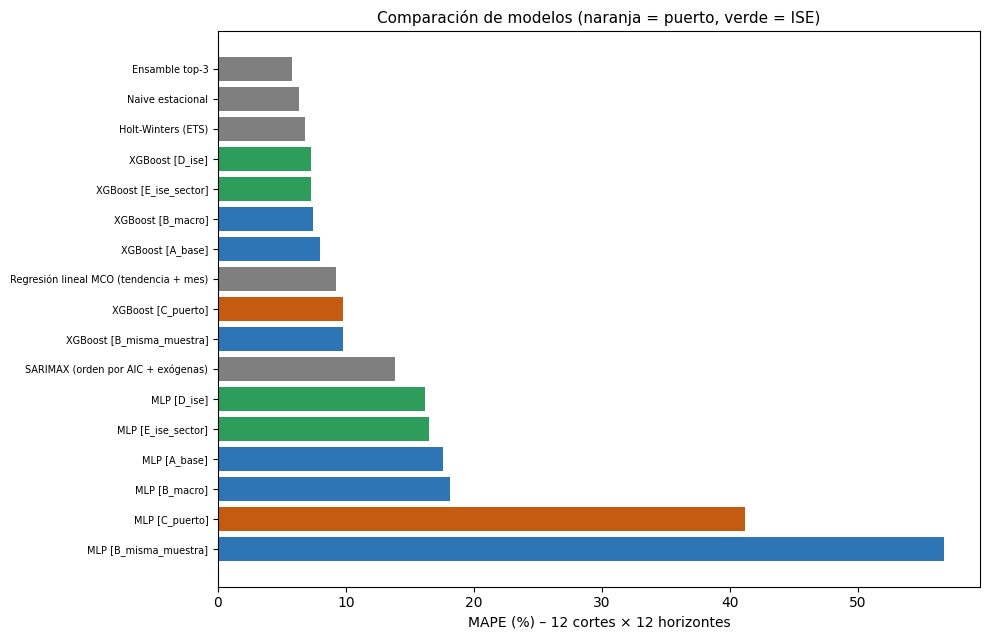

In [32]:
abl = metricas.reset_index()
abl = abl[abl["modelo"].str.contains(r"\[")].copy()
abl["algoritmo"] = abl["modelo"].str.extract(r"^(.*?) \[")[0]
abl["set"] = abl["modelo"].str.extract(r"\[(.*)\]")[0]
orden_sets = ["A_base", "B_macro", "B_misma_muestra", "C_puerto", "D_ise", "E_ise_sector"]
tabla_abl = abl.pivot(index="algoritmo", columns="set", values="MAPE_%")[orden_sets]
print("MAPE (%) según variables incluidas (backtesting completo):")
print(tabla_abl.round(2))

abl_h = metricas_hold.reset_index()
abl_h = abl_h[abl_h["modelo"].str.contains(r"\[")].copy()
abl_h["algoritmo"] = abl_h["modelo"].str.extract(r"^(.*?) \[")[0]
abl_h["set"] = abl_h["modelo"].str.extract(r"\[(.*)\]")[0]
tabla_abl_h = abl_h.pivot(index="algoritmo", columns="set", values="MAPE_%")[orden_sets]
print("\nMAPE (%) según variables incluidas (solo ventana de validación):")
print(tabla_abl_h.round(2))

# prueba pareada (mismos corte × horizonte): ¿el modelo con ISE se equivoca menos que B_macro?
def comparar(a, b):
    xa = bt[bt["modelo"] == a].set_index(["corte", "h"])[["ape"]]
    xb = bt[bt["modelo"] == b].set_index(["corte", "h"])[["ape"]]
    j = xa.join(xb, lsuffix="_a", rsuffix="_b", how="inner")
    dif = (j["ape_a"] - j["ape_b"]) * 100
    return pd.Series({"n_pares": len(j), "dif_MAPE_pp": dif.mean(), "% pares donde mejora": (dif < 0).mean() * 100})
filas_c = []
for algo in modelos_ml():
    for s_ in ("C_puerto", "D_ise", "E_ise_sector"):
        r_ = comparar(f"{algo} [{s_}]", f"{algo} [B_macro]" if s_ != "C_puerto" else f"{algo} [B_misma_muestra]")
        filas_c.append(pd.concat([pd.Series({"algoritmo": algo, "comparación": f"{s_} vs " + ("B_misma_muestra" if s_ == "C_puerto" else "B_macro")}), r_]))
prueba_pareada = pd.DataFrame(filas_c).round(2)
print("\nPrueba pareada (dif_MAPE_pp < 0 = mejora al agregar la variable; los pares no son independientes, es indicativa):")
print(prueba_pareada.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6.5))
orden = metricas["MAPE_%"].sort_values(ascending=False)
colores = ["#c55a11" if "C_puerto" in n else "#2e9d5b" if ("D_ise" in n or "E_ise" in n) else "#2e75b6" if "[" in n else "#7f7f7f" for n in orden.index]
ax.barh(orden.index, orden.values, color=colores)
ax.set_xlabel("MAPE (%) – 12 cortes × 12 horizontes")
ax.set_title("Comparación de modelos (naranja = puerto, verde = ISE)", fontsize=11); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig2_comparacion_modelos.png", dpi=130); plt.show()

## FASE 6 · Despliegue: pronóstico de tráfico

### 6.1 Pronóstico a 12 meses con el modelo seleccionado. El modelo final es el ensamble definido en 5.1 (configurable con `MODELO_FINAL`).

In [33]:
MODELO_FINAL = "Ensamble top-3"        # >>> NUEVO: configurable (p. ej. "Ridge [B_macro]")
mejor = MODELO_FINAL
print("Modelo seleccionado:", mejor, "| componentes:", top3 if mejor == "Ensamble top-3" else "—")

def prediccion_final(nombre, T):
    if nombre == "Ensamble top-3":
        return np.mean([prediccion_final(n, T) for n in top3], axis=0)
    return MODELOS[nombre](T)

T = N - 1
yh = prediccion_final(mejor, T)
fechas = pd.date_range(d.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
fc = pd.DataFrame({"fecha": fechas, "trafico_pred": np.exp(yh) * dias[T + 1:T + 1 + H]})

# Intervalo empírico (P10-P90) a partir de los errores logarítmicos del backtesting del modelo elegido
b = bt[bt["modelo"] == mejor].copy()
b["le"] = np.log(b["real"] / b["pred"])
b["grupo"] = pd.cut(b["h"], [0, 4, 8, 12], labels=[0, 1, 2]).astype(int)
q = b.groupby("grupo")["le"].quantile([.1, .9]).unstack()
g = pd.cut(np.arange(1, H + 1), [0, 4, 8, 12], labels=[0, 1, 2]).astype(int)
fc["p10"] = fc["trafico_pred"] * np.exp(q.loc[g, 0.1].values)
fc["p90"] = fc["trafico_pred"] * np.exp(q.loc[g, 0.9].values)
hist12 = m.loc[d.index[-1] - pd.DateOffset(months=11):d.index[-1]]
print(f"Tráfico últimos 12 m reales: {hist12['trafico_total'].sum():,.0f} | pronóstico próximos 12 m: {fc['trafico_pred'].sum():,.0f} "
      f"({fc['trafico_pred'].sum() / hist12['trafico_total'].sum() - 1:+.1%})")
fc.round(0)

Modelo seleccionado: Ensamble top-3 | componentes: ['Holt-Winters (ETS)', 'Regresión lineal MCO (tendencia + mes)', 'XGBoost [D_ise]']
Tráfico últimos 12 m reales: 14,263,495 | pronóstico próximos 12 m: 14,967,974 (+4.9%)


,fecha,trafico_pred,p10,p90
0,2026-01-01,1389183.0,1261379.0,1501730.0
1,2026-02-01,1078858.0,979604.0,1166264.0
2,2026-03-01,1207018.0,1095973.0,1304807.0
3,2026-04-01,1203424.0,1092710.0,1300921.0
4,2026-05-01,1085269.0,995094.0,1115232.0
5,2026-06-01,1244297.0,1140908.0,1278650.0
6,2026-07-01,1312763.0,1203685.0,1349006.0
7,2026-08-01,1287602.0,1180615.0,1323151.0
8,2026-09-01,1182939.0,1073918.0,1186434.0
9,2026-10-01,1289182.0,1170369.0,1292990.0


6.3 Gráficos de resultados y exportación. Se agregan las figuras de escenarios, categorías y sensibilidad y hojas nuevas al Excel de resultados.

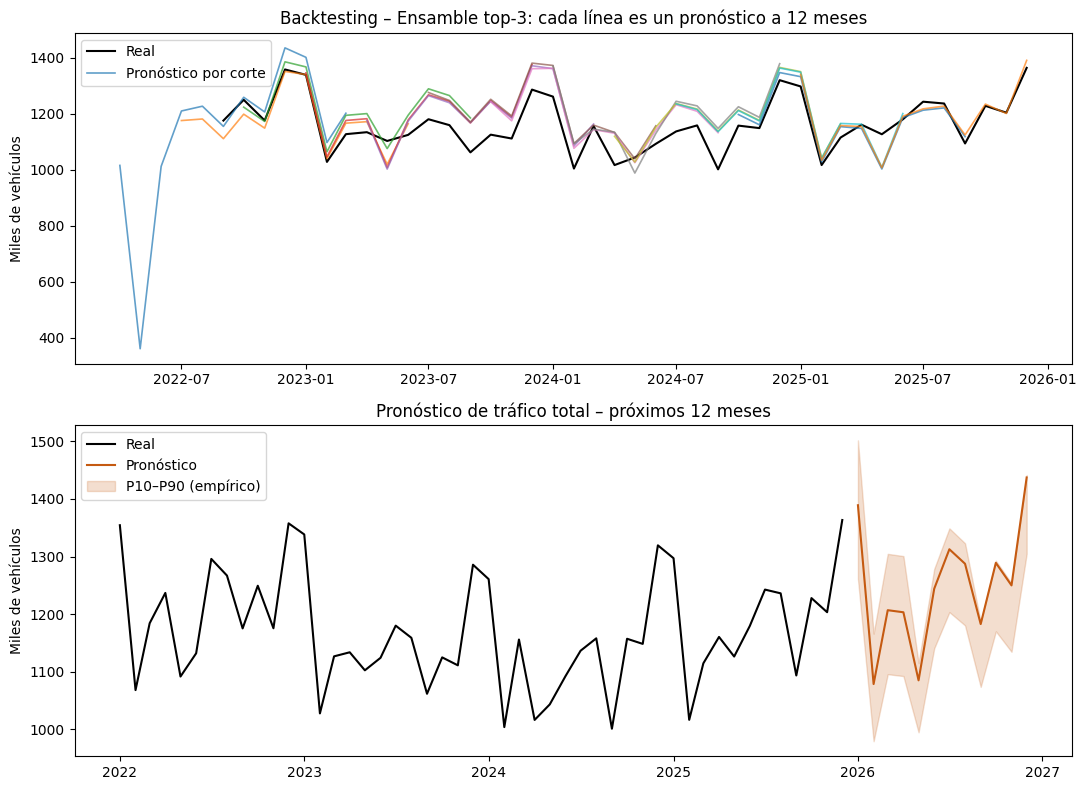

Resultados exportados a C:\Users\maria\OneDrive\Escritorio\Data Set Trafico\Data Set/resultados


In [36]:
fig, ax = plt.subplots(2, 1, figsize=(11, 8))
bb = bt[bt["modelo"] == mejor]
ax[0].plot(d.index[-40:], d["trafico_total"].values[-40:] / 1e3, color="black", label="Real")
for i, (c, gdf) in enumerate(bb.groupby("corte")):
    ax[0].plot(gdf["fecha"], gdf["pred"] / 1e3, alpha=.7, lw=1.2, label="Pronóstico por corte" if i == 0 else None)
ax[0].set_title(f"Backtesting – {mejor}: cada línea es un pronóstico a 12 meses"); ax[0].set_ylabel("Miles de vehículos"); ax[0].legend()
ax[1].plot(d.index[-48:], d["trafico_total"].values[-48:] / 1e3, color="black", label="Real")
ax[1].plot(fc["fecha"], fc["trafico_pred"] / 1e3, color="#c55a11", label="Pronóstico")
ax[1].fill_between(fc["fecha"], fc["p10"] / 1e3, fc["p90"] / 1e3, color="#c55a11", alpha=.2, label="P10–P90 (empírico)")
ax[1].set_title("Pronóstico de tráfico total – próximos 12 meses"); ax[1].set_ylabel("Miles de vehículos"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_backtest_y_pronostico.png", dpi=130); plt.show()


fc.round(0).to_csv(f"{OUT_DIR}/pronostico_trafico_ingresos.csv", index=False)
with pd.ExcelWriter(f"{OUT_DIR}/resultados_modelos.xlsx") as w:
    metricas.reset_index().to_excel(w, sheet_name="metricas", index=False)
    metricas_hold.reset_index().to_excel(w, sheet_name="metricas_holdout", index=False)               # >>> NUEVO
    tabla_abl.round(2).reset_index().to_excel(w, sheet_name="ablacion", index=False)                  # >>> MODIFICADO (nombre y columnas)
    tabla_abl_h.round(2).reset_index().to_excel(w, sheet_name="ablacion_holdout", index=False)        # >>> NUEVO
    prueba_pareada.to_excel(w, sheet_name="prueba_pareada", index=False)                              # >>> NUEVO
    corr_ise.to_excel(w, sheet_name="corr_ise", index=False)                                          # >>> NUEVO
    fc.to_excel(w, sheet_name="pronostico", index=False)
    tabla_esc.reset_index().rename(columns={"index": "escenario"}).to_excel(w, sheet_name="escenarios", index=False)   # >>> NUEVO
    sens.round(2).reset_index().to_excel(w, sheet_name="sensibilidad", index=False)                   # >>> NUEVO
    cat_base.reset_index().rename(columns={"index": "fecha"}).to_excel(w, sheet_name="ingreso_categoria_base", index=False)  # >>> NUEVO
    bt.drop(columns=["err", "ape"]).to_excel(w, sheet_name="backtest_detalle", index=False)
print("Resultados exportados a", OUT_DIR)